#Download Data set from kaggle

In [1]:
import os
!pip install -q kagglehub

import kagglehub

path = kagglehub.dataset_download("andradaolteanu/gtzan-dataset-music-genre-classification")
print("Path to dataset files:", path)

100%|██████████| 1.21G/1.21G [00:57<00:00, 22.7MB/s]


Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/andradaolteanu/gtzan-dataset-music-genre-classification/versions/1


In [2]:
import os

path = "/root/.cache/kagglehub/datasets/andradaolteanu/gtzan-dataset-music-genre-classification/versions/1"

print("Files in dataset directory:")
print(os.listdir(path))

Files in dataset directory:
['Data']


In [3]:
import shutil

shutil.copytree(path, "/content/gtzan_data")

print("Copied dataset to /content/gtzan_data")

Copied dataset to /content/gtzan_data


#Imports

In [44]:
import os
import hashlib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

# Scikit-Learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

# TensorFlow / Keras
import tensorflow as tf

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    Dense,
    GlobalAveragePooling2D,
    Dropout,
    RandomZoom,
    RandomTranslation,
    RandomContrast
)

from tensorflow.keras.optimizers import Adam

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

warnings.filterwarnings("ignore")

plt.style.use("dark_background")

SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)


#Load Data set

In [45]:
DATASET_PATH = "/content/gtzan_data/Data/images_original"

print("Dataset path:", DATASET_PATH)
print("Path exists:", os.path.exists(DATASET_PATH))

print("\nDataset folders:")

for folder in sorted(os.listdir(DATASET_PATH)):
    folder_path = os.path.join(DATASET_PATH, folder)

    if os.path.isdir(folder_path):
        print(" -", folder)

Dataset path: /content/gtzan_data/Data/images_original
Path exists: True

Dataset folders:
 - blues
 - classical
 - country
 - disco
 - hiphop
 - jazz
 - metal
 - pop
 - reggae
 - rock


In [46]:
filepaths = []
labels = []

VALID_EXTENSIONS = (
    ".png",
    ".jpg",
    ".jpeg",
    ".bmp",
    ".webp"
)

for genre in sorted(os.listdir(DATASET_PATH)):

    genre_path = os.path.join(
        DATASET_PATH,
        genre
    )

    if not os.path.isdir(genre_path):
        continue

    for filename in os.listdir(genre_path):

        filepath = os.path.join(
            genre_path,
            filename
        )

        if (
            os.path.isfile(filepath)
            and filename.lower().endswith(VALID_EXTENSIONS)
        ):

            filepaths.append(filepath)
            labels.append(genre)


df = pd.DataFrame({
    "Filepath": filepaths,
    "Label": labels
})

print("Total images:", len(df))

print("\nClass distribution:")
print(
    df["Label"]
    .value_counts()
    .sort_index()
)

Total images: 999

Class distribution:
Label
blues        100
classical    100
country      100
disco        100
hiphop       100
jazz          99
metal        100
pop          100
reggae       100
rock         100
Name: count, dtype: int64


#Data set cleaning

In [47]:
def calculate_file_hash(filepath):
    """
    Calculate MD5 hash based on the exact file bytes.
    """

    hash_md5 = hashlib.md5()

    with open(filepath, "rb") as f:

        for chunk in iter(
            lambda: f.read(8192),
            b""
        ):
            hash_md5.update(chunk)

    return hash_md5.hexdigest()


print("Calculating image hashes...")

df["FileHash"] = df["Filepath"].apply(
    calculate_file_hash
)

duplicate_mask = df.duplicated(
    subset="FileHash",
    keep="first"
)

num_duplicates = duplicate_mask.sum()

print("Exact duplicate images found:", num_duplicates)

# Remove duplicates
df = df[
    ~duplicate_mask
].copy()

df = df.reset_index(drop=True)

print("Dataset size after duplicate removal:", len(df))

Calculating image hashes...
Exact duplicate images found: 14
Dataset size after duplicate removal: 985


In [48]:
duplicate_hash_groups = (
    df.groupby("FileHash")["Label"]
    .nunique()
)

cross_class_duplicates = (
    duplicate_hash_groups > 1
).sum()

print(
    "Exact duplicate hashes shared across different classes:",
    cross_class_duplicates
)

Exact duplicate hashes shared across different classes: 0


In [49]:
corrupted_files = []

for filepath in df["Filepath"]:

    try:

        with Image.open(filepath) as img:
            img.load()

    except Exception:

        corrupted_files.append(filepath)


print(
    "Corrupted images found:",
    len(corrupted_files)
)

if corrupted_files:

    df = df[
        ~df["Filepath"].isin(corrupted_files)
    ].copy()

    df = df.reset_index(drop=True)


print(
    "Final dataset size:",
    len(df)
)

Corrupted images found: 0
Final dataset size: 985


Final dataset shape: (985, 3)

Final class distribution:
Label
blues        100
classical    100
country      100
disco         99
hiphop        98
jazz          99
metal         93
pop           98
reggae        99
rock          99
Name: count, dtype: int64


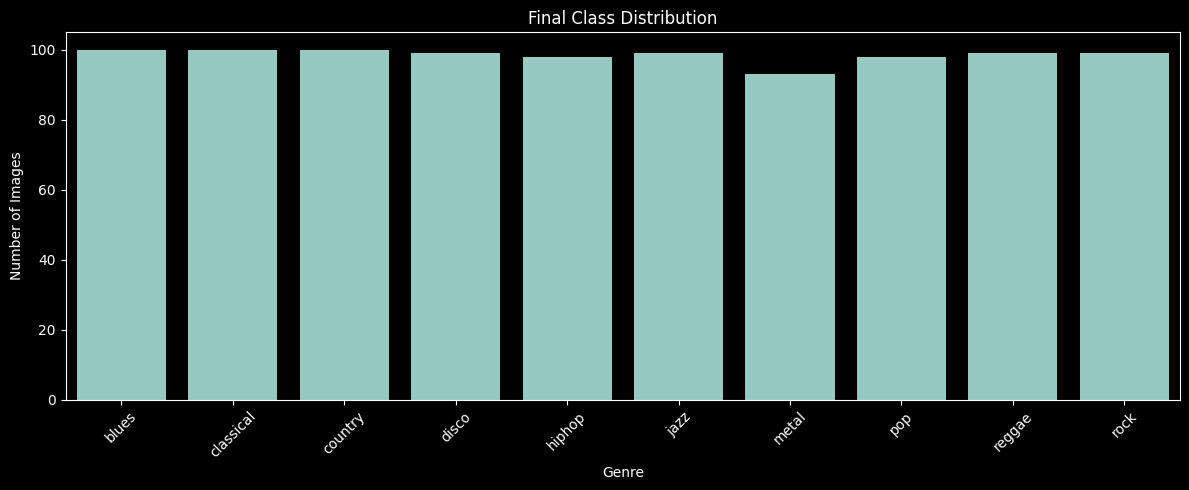

In [50]:
print("Final dataset shape:", df.shape)

print("\nFinal class distribution:")

print(
    df["Label"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(12, 5))

sns.countplot(
    data=df,
    x="Label",
    order=sorted(df["Label"].unique())
)

plt.title("Final Class Distribution")

plt.xlabel("Genre")
plt.ylabel("Number of Images")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

#Visualization

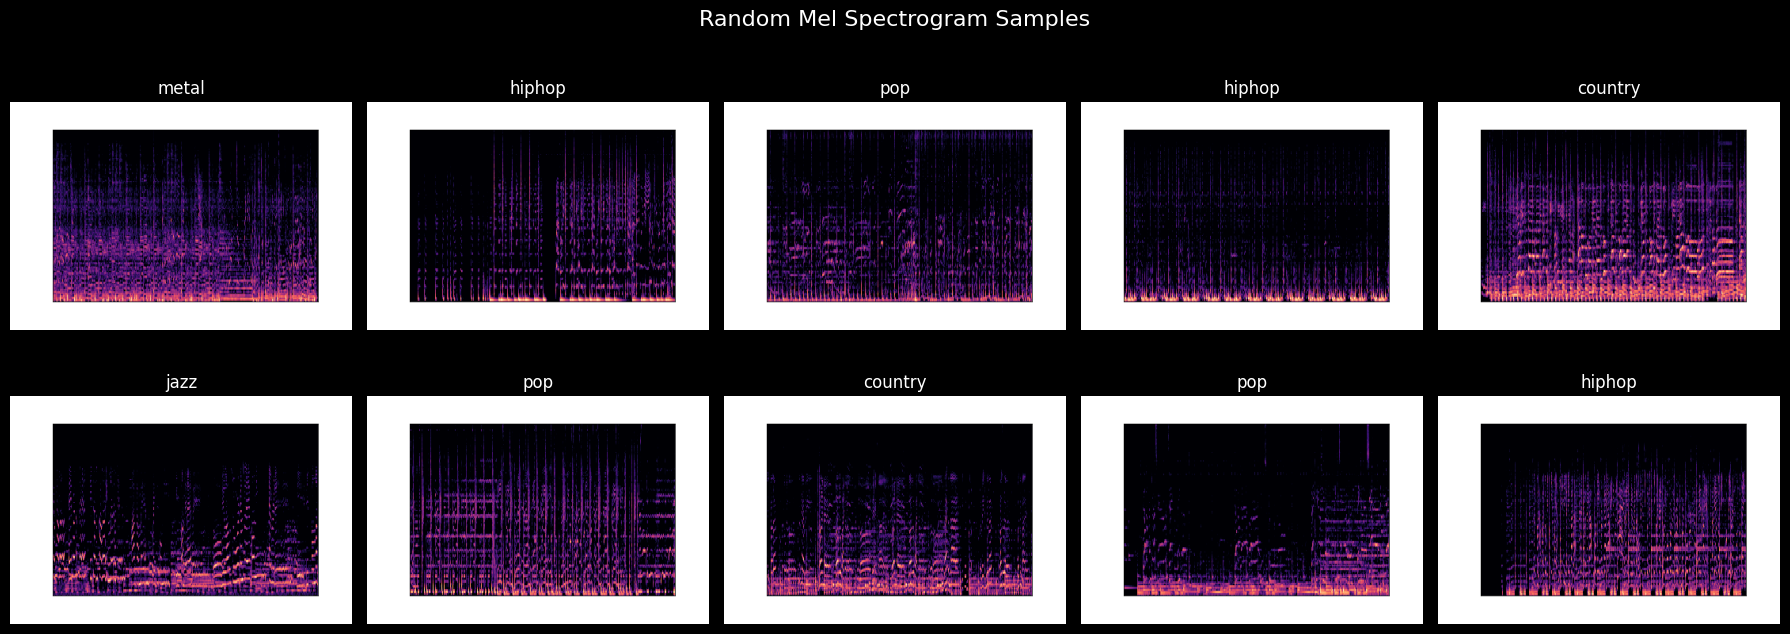

In [51]:
fig, axes = plt.subplots(
    2,
    5,
    figsize=(18, 7)
)

random_indices = np.random.choice(
    len(df),
    size=10,
    replace=False
)

for ax, idx in zip(
    axes.flat,
    random_indices
):

    image = Image.open(
        df["Filepath"].iloc[idx]
    )

    ax.imshow(image)

    ax.set_title(
        df["Label"].iloc[idx]
    )

    ax.axis("off")


plt.suptitle(
    "Random Mel Spectrogram Samples",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [52]:
widths = []
heights = []
modes = []

for filepath in df["Filepath"]:

    with Image.open(filepath) as img:

        widths.append(img.width)
        heights.append(img.height)
        modes.append(img.mode)


df["Width"] = widths
df["Height"] = heights
df["Mode"] = modes


print("Image widths:")
print(df["Width"].value_counts().head())

print("\nImage heights:")
print(df["Height"].value_counts().head())

print("\nImage color modes:")
print(df["Mode"].value_counts())

Image widths:
Width
432    985
Name: count, dtype: int64

Image heights:
Height
288    985
Name: count, dtype: int64

Image color modes:
Mode
RGBA    985
Name: count, dtype: int64


#Encoding

In [53]:
le = LabelEncoder()

df["Encoded_Label"] = le.fit_transform(
    df["Label"]
)

num_classes = len(
    le.classes_
)

print("Number of classes:", num_classes)

print("\nLabel Mapping:")

for index, class_name in enumerate(
    le.classes_
):

    print(
        f"{class_name} -> {index}"
    )

Number of classes: 10

Label Mapping:
blues -> 0
classical -> 1
country -> 2
disco -> 3
hiphop -> 4
jazz -> 5
metal -> 6
pop -> 7
reggae -> 8
rock -> 9


#Train Test Split

In [54]:
X = df["Filepath"].to_numpy()
y = df["Encoded_Label"].to_numpy()



X_train, X_temp, y_train, y_temp = train_test_split(

    X,
    y,

    test_size=0.30,

    random_state=SEED,

    stratify=y
)


X_val, X_test, y_val, y_test = train_test_split(

    X_temp,
    y_temp,

    test_size=0.50,

    random_state=SEED,

    stratify=y_temp
)


print("Train samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

print(
    "\nTotal:",
    len(X_train) + len(X_val) + len(X_test)
)

Train samples: 689
Validation samples: 148
Test samples: 148

Total: 985


In [55]:
train_dist = (
    pd.Series(y_train)
    .value_counts()
    .sort_index()
)

val_dist = (
    pd.Series(y_val)
    .value_counts()
    .sort_index()
)

test_dist = (
    pd.Series(y_test)
    .value_counts()
    .sort_index()
)


split_distribution = pd.DataFrame({

    "Train": train_dist,

    "Validation": val_dist,

    "Test": test_dist
})


split_distribution.index = le.classes_

print(split_distribution)

           Train  Validation  Test
blues         70          15    15
classical     70          15    15
country       70          15    15
disco         69          15    15
hiphop        69          14    15
jazz          69          15    15
metal         65          14    14
pop           69          15    14
reggae        69          15    15
rock          69          15    15


#Image sizing and Batch size

In [66]:
IMG_SIZE = (288, 432)

BATCH_SIZE = 16

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Image size: (288, 432)
Batch size: 16


In [67]:

def parse_image(filename, label):

    image_string = tf.io.read_file(
        filename
    )

    image = tf.image.decode_image(
        image_string,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    image = tf.cast(
        image,
        tf.float32
    )

    image = tf.keras.applications.mobilenet_v2.preprocess_input(
        image
    )

    return image, label

#Build Data set

In [68]:

train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
)

train_dataset = train_dataset.map(
    parse_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_dataset = train_dataset.shuffle(
    buffer_size=len(X_train),
    seed=SEED
)

train_dataset = train_dataset.batch(
    BATCH_SIZE
)

train_dataset = train_dataset.prefetch(
    tf.data.AUTOTUNE
)


val_dataset = tf.data.Dataset.from_tensor_slices(
    (X_val, y_val)
)

val_dataset = val_dataset.map(
    parse_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_dataset = val_dataset.batch(
    BATCH_SIZE
)

val_dataset = val_dataset.prefetch(
    tf.data.AUTOTUNE
)


test_dataset = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test)
)

test_dataset = test_dataset.map(
    parse_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_dataset = test_dataset.batch(
    BATCH_SIZE
)

test_dataset = test_dataset.prefetch(
    tf.data.AUTOTUNE
)


print("tf.data pipelines created successfully.")

tf.data pipelines created successfully.


In [69]:
# ==========================================
#Data Augmentation
# ==========================================

data_augmentation = Sequential([

    RandomContrast(
        factor=0.05
    )

], name="spectrogram_augmentation")


print("Data augmentation ready.")

Data augmentation ready.


#Transfer Learning using mobile net model

In [70]:
print(
    "Loading MobileNetV2 pretrained on ImageNet..."
)

base_model = tf.keras.applications.MobileNetV2(

    input_shape=(
        IMG_SIZE[0],
        IMG_SIZE[1],
        3
    ),

    include_top=False,

    weights="imagenet"
)


# Freeze pretrained layers
base_model.trainable = False


print("Base model loaded.")
print("Base model trainable:", base_model.trainable)

Loading MobileNetV2 pretrained on ImageNet...
Base model loaded.
Base model trainable: False


In [81]:
model = Sequential([

    tf.keras.Input(
        shape=(
            IMG_SIZE[0],
            IMG_SIZE[1],
            3
        )
    ),

    #data_augmentation,

    base_model,

    GlobalAveragePooling2D(),

    Dense(
        256,
        activation="relu"
    ),

    Dropout(0.35),

    Dense(
        num_classes,
        activation="softmax"
    )

], name="GTZAN_MobileNetV2")


model.summary()

Model: "GTZAN_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 9, 14, 1280)    │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_6      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,588,490 (9.87 MB)

 Trainable params: 330,506 (1.26 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [82]:
optimizer = Adam(
    learning_rate=1e-3
)


model.compile(

    optimizer=optimizer,

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)


print("Model compiled successfully.")

Model compiled successfully.


In [83]:
early_stopping = EarlyStopping(

    monitor="val_loss",

    patience=10,

    restore_best_weights=True,

    verbose=1
)


lr_scheduler = ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.5,

    patience=3,

    min_lr=1e-6,

    verbose=1
)

#Train

In [84]:
EPOCHS = 30

history = model.fit(

    train_dataset,

    validation_data=val_dataset,

    epochs=EPOCHS,

    callbacks=[
        early_stopping,
        lr_scheduler
    ],

    verbose=1
)

Epoch 1/30
44/44 ━━━━━━━━━━━━━━━━━━━━ 42s 592ms/step - accuracy: 0.3367 - loss: 1.8980 - val_accuracy: 0.5676 - val_loss: 1.2944 - learning_rate: 0.0010
Epoch 2/30
44/44 ━━━━━━━━━━━━━━━━━━━━ 6s 76ms/step - accuracy: 0.5515 - loss: 1.3208 - val_accuracy: 0.6554 - val_loss: 1.0964 - learning_rate: 0.0010
Epoch 3/30
44/44 ━━━━━━━━━━━━━━━━━━━━ 6s 84ms/step - accuracy: 0.5980 - loss: 1.1502 - val_accuracy: 0.6622 - val_loss: 1.0197 - learning_rate: 0.0010
Epoch 4/30
44/44 ━━━━━━━━━━━━━━━━━━━━ 5s 61ms/step - accuracy: 0.6517 - loss: 1.0815 - val_accuracy: 0.6554 - val_loss: 1.0478 - learning_rate: 0.0010
Epoch 5/30
44/44 ━━━━━━━━━━━━━━━━━━━━ 6s 60ms/step - accuracy: 0.6763 - loss: 0.9811 - val_accuracy: 0.7297 - val_loss: 0.8791 - learning_rate: 0.0010
Epoch 6/30
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - accuracy: 0.6836 - loss: 0.9335 - val_accuracy: 0.7027 - val_loss: 0.9014 - learning_rate: 0.0010
Epoch 7/30
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - accuracy: 0.6938 - loss: 0.8657 - val_a

In [85]:
test_loss, test_accuracy = model.evaluate(
    test_dataset,
    verbose=0
)

print("=" * 50)
print("FINAL TEST RESULTS")
print("=" * 50)



print(
    f"Test Accuracy : {test_accuracy:.4f}"
)

FINAL TEST RESULTS
Test Accuracy : 0.7162


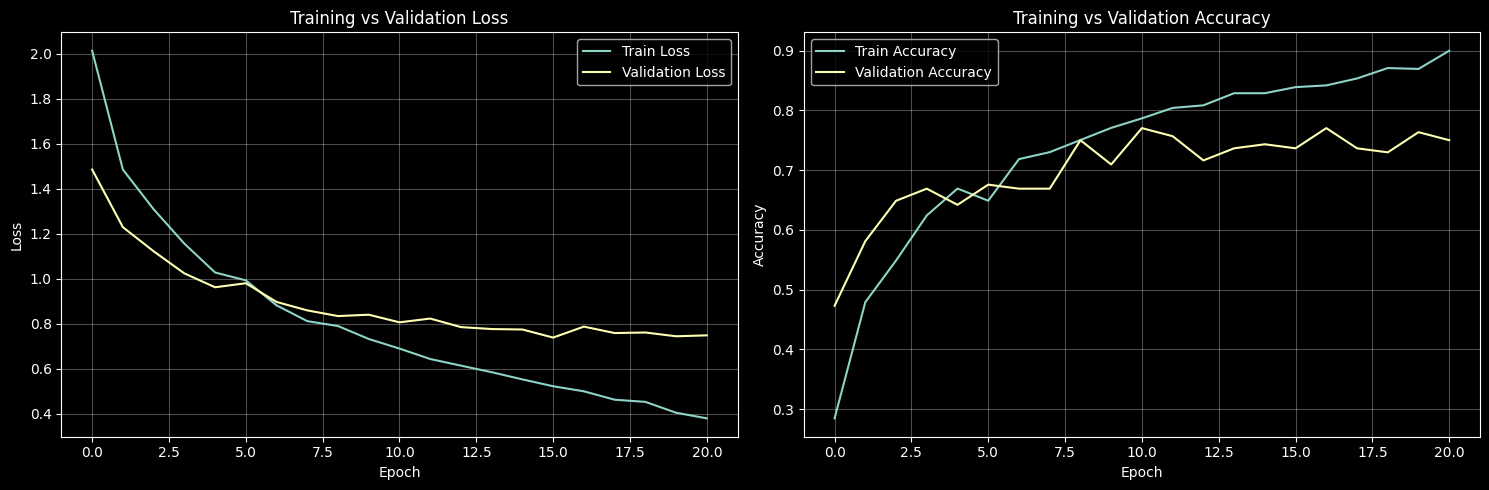

In [26]:

history_df = pd.DataFrame(
    history.history
)


fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5)
)


# -------------------------
# Loss
# -------------------------

axes[0].plot(
    history_df["loss"],
    label="Train Loss"
)

axes[0].plot(
    history_df["val_loss"],
    label="Validation Loss"
)

axes[0].set_title(
    "Training vs Validation Loss"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")

axes[0].legend()
axes[0].grid(alpha=0.3)


# -------------------------
# Accuracy
# -------------------------

axes[1].plot(
    history_df["accuracy"],
    label="Train Accuracy"
)

axes[1].plot(
    history_df["val_accuracy"],
    label="Validation Accuracy"
)

axes[1].set_title(
    "Training vs Validation Accuracy"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")

axes[1].legend()
axes[1].grid(alpha=0.3)


plt.tight_layout()
plt.show()

#CNN From Scratch

In [33]:
from tensorflow.keras import layers, models

custom_cnn = models.Sequential([

    tf.keras.Input(
        shape=(288, 432, 3)
    ),

    # -------------------------
    # Block 1
    # -------------------------
    layers.Conv2D(
        32,
        (3, 3),
        padding="same",
        activation="relu"
    ),

    layers.BatchNormalization(),

    layers.MaxPooling2D(
        (2, 2)
    ),


    # -------------------------
    # Block 2
    # -------------------------
    layers.Conv2D(
        64,
        (3, 3),
        padding="same",
        activation="relu"
    ),

    layers.BatchNormalization(),

    layers.MaxPooling2D(
        (2, 2)
    ),


    # -------------------------
    # Block 3
    # -------------------------
    layers.Conv2D(
        128,
        (3, 3),
        padding="same",
        activation="relu"
    ),

    layers.BatchNormalization(),

    layers.MaxPooling2D(
        (2, 2)
    ),


    # -------------------------
    # Block 4
    # -------------------------
    layers.Conv2D(
        256,
        (3, 3),
        padding="same",
        activation="relu"
    ),

    layers.BatchNormalization(),

    layers.MaxPooling2D(
        (2, 2)
    ),


    # -------------------------
    # Classification Head
    # -------------------------

    layers.GlobalAveragePooling2D(),

    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dropout(
        0.3
    ),

    layers.Dense(
        num_classes,
        activation="softmax"
    )

], name="Custom_CNN")


custom_cnn.summary()

Model: "Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 288, 432, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 288, 432, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 144, 216, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 144, 216, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 144, 216, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 72, 108, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 72, 108, 128)   │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 72, 108, 128)   │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 36, 54, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 36, 54, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 36, 54, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 18, 27, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 424,522 (1.62 MB)

 Trainable params: 423,562 (1.62 MB)

 Non-trainable params: 960 (3.75 KB)

In [34]:
custom_cnn.compile(

    optimizer=Adam(
        learning_rate=1e-3
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

print("Custom CNN compiled successfully.")

Custom CNN compiled successfully.


In [35]:


custom_early_stopping = EarlyStopping(

    monitor="val_loss",

    patience=7,

    restore_best_weights=True,

    verbose=1
)


custom_lr_scheduler = ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.5,

    patience=3,

    min_lr=1e-6,

    verbose=1
)

In [39]:


CUSTOM_EPOCHS = 30

custom_history = custom_cnn.fit(

    train_dataset,

    validation_data=val_dataset,

    epochs=CUSTOM_EPOCHS,

    callbacks=[
        custom_early_stopping,
        custom_lr_scheduler
    ],

    verbose=1
)

Epoch 1/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 43s 912ms/step - accuracy: 0.2525 - loss: 2.0636 - val_accuracy: 0.1081 - val_loss: 2.2729 - learning_rate: 0.0010
Epoch 2/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 181ms/step - accuracy: 0.3599 - loss: 1.7380 - val_accuracy: 0.1014 - val_loss: 2.9384 - learning_rate: 0.0010
Epoch 3/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 6s 199ms/step - accuracy: 0.4543 - loss: 1.5452 - val_accuracy: 0.1014 - val_loss: 4.2556 - learning_rate: 0.0010
Epoch 4/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step - accuracy: 0.4421 - loss: 1.4405
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
22/22 ━━━━━━━━━━━━━━━━━━━━ 10s 185ms/step - accuracy: 0.4673 - loss: 1.4229 - val_accuracy: 0.1014 - val_loss: 4.9714 - learning_rate: 0.0010
Epoch 5/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 10s 184ms/step - accuracy: 0.5167 - loss: 1.3216 - val_accuracy: 0.1014 - val_loss: 5.4313 - learning_rate: 5.0000e-04
Epoch 6/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 188ms/step - accuracy: 0.5515 - loss: 1.3

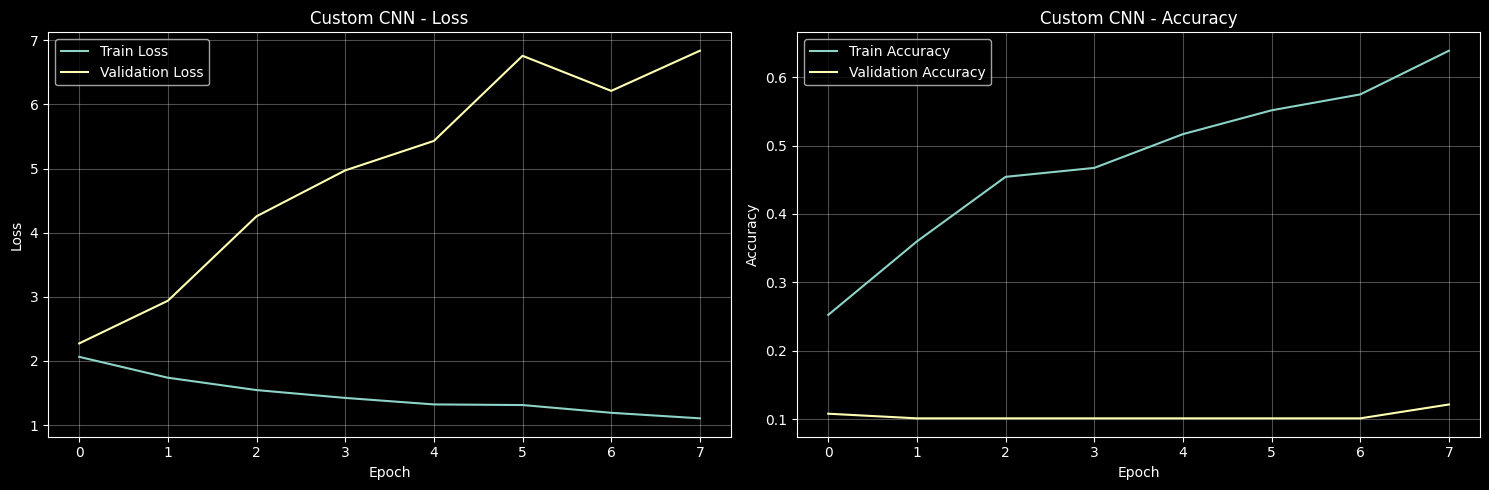

In [40]:


custom_history_df = pd.DataFrame(
    custom_history.history
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5)
)


# Loss
axes[0].plot(
    custom_history_df["loss"],
    label="Train Loss"
)

axes[0].plot(
    custom_history_df["val_loss"],
    label="Validation Loss"
)

axes[0].set_title(
    "Custom CNN - Loss"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")

axes[0].legend()
axes[0].grid(alpha=0.3)


# Accuracy
axes[1].plot(
    custom_history_df["accuracy"],
    label="Train Accuracy"
)

axes[1].plot(
    custom_history_df["val_accuracy"],
    label="Validation Accuracy"
)

axes[1].set_title(
    "Custom CNN - Accuracy"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")

axes[1].legend()
axes[1].grid(alpha=0.3)


plt.tight_layout()
plt.show()

In [43]:


test_loss_custom, test_accuracy_custom = custom_cnn.evaluate(
    test_dataset,
    verbose=0
)

print("=" * 50)
print("CUSTOM CNN - FINAL TEST RESULTS")
print("=" * 50)

print(
    f"Test Accuracy : {test_accuracy_custom:.4f}"
)

CUSTOM CNN - FINAL TEST RESULTS
Test Accuracy : 0.1014
